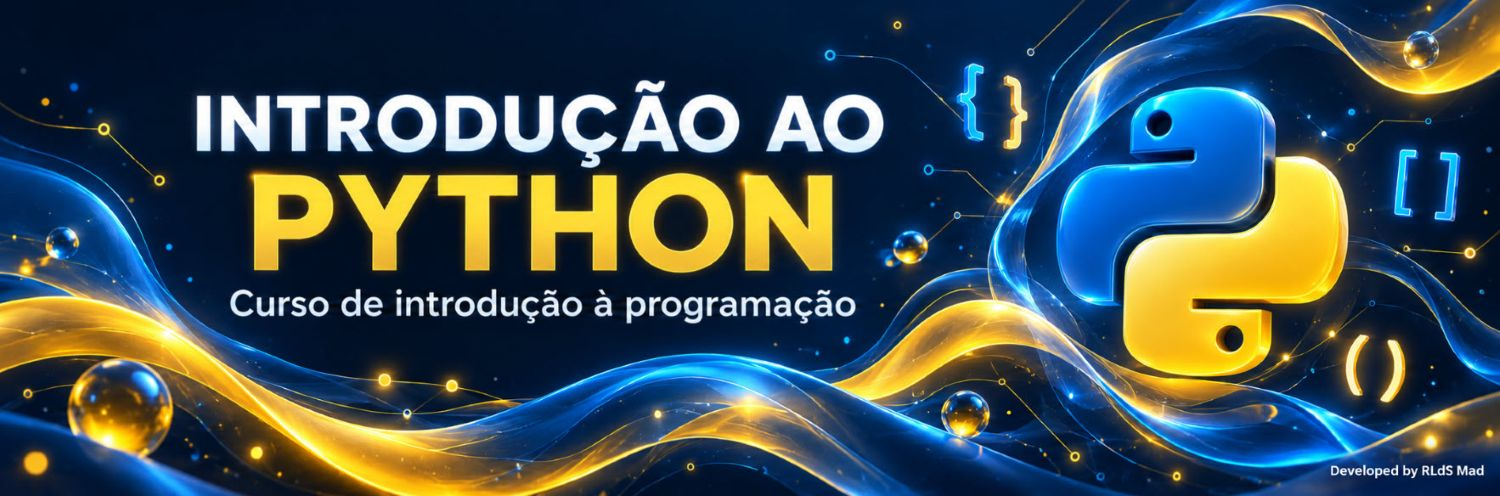

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_2_avancado/RLdS_N2_04_ScikitLearn_Classificacao.ipynb)



# Nível avançado · Módulo 4 – Scikit-learn: classificação e seleção de modelos
## De probabilidades a decisões avaliadas em dados novos

Este módulo continua o estudo iniciado em **Fundamentos e regressão**. O foco é scikit-learn; os conhecimentos de NumPy são aplicados à manipulação de entradas, probabilidades e previsões, enquanto Pandas organiza variáveis numéricas e categóricas.

**Pré-requisitos:** `fit` e `predict`; treino versus avaliação; formas de arrays; máscaras; DataFrames; noção de pipeline. 

**Duração sugerida:** 10–14 horas, com exercícios.

**Objetivos:** construir classificadores; interpretar erros por classe; trabalhar com categorias e ausências; comparar pipelines; selecionar hiperparâmetros; escolher um limiar fora do treino; avaliar uma política final sem reutilizar o teste para decisões.

### Como utilizar
Executa de cima para baixo em Jupyter, VS Code ou Colab. Os dados são sintéticos e gerados no notebook. Não dependemos de ficheiros dos módulos anteriores. Depois de instalar as dependências, o percurso funciona sem Internet. As figuras estão incorporadas nas saídas.

As células dos exercícios são facultativas; as soluções funcionam sem as preencher. As exportações criam ou substituem ficheiros de demonstração em `sklearn02_lab`. Guarda ficheiros teus noutro local. No Colab, descarrega resultados antes de terminar a sessão. Para reproduzir, reinicia o kernel e executa tudo.

### Índice
1. Classificação: alvo, probabilidades e decisões
2. Cenário e separação treino/validação/teste
3. Referência e métricas de classificação
4. Categorias, OneHotEncoder e ColumnTransformer
5. Regressão logística, kNN e árvores
6. Validação cruzada estratificada e comparação
7. GridSearchCV e RandomizedSearchCV
8. Probabilidades, curvas ROC e precision–recall
9. Seleção de limiar com custos explícitos
10. Avaliação final no teste
11. Miniprojeto, contratos e exportação
12. Extensão opcional multiclasse
13. Soluções, consulta e referências

**Protocolo:** ajustar e pesquisar nos 60% de treino → escolher o limiar nos 20% de validação → avaliar uma vez nos 20% de teste. Não reajustamos o modelo depois de escolher o limiar, para não alterar a escala das probabilidades usada nessa escolha.

## 1. Preparação do ambiente
Descomenta a instalação apenas se necessário e reinicia o kernel depois. Usa o kernel associado ao ambiente onde instalaste o pacote. A instalação chama-se `scikit-learn`, enquanto os imports usam `sklearn`. Os exemplos usam `OneHotEncoder(sparse_output=False)`, disponível em scikit-learn 1.2+.

In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install "scikit-learn>=1.4" numpy pandas matplotlib

In [2]:
from pathlib import Path
from io import BytesIO
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve, brier_score_loss, log_loss)

PASTA = Path.cwd() / "sklearn02_lab"
PASTA.mkdir(exist_ok=True)
VERSOES = {p: version(p) for p in ["scikit-learn", "numpy", "pandas", "matplotlib"]}
VERSOES["python"] = platform.python_version()
display(pd.Series(VERSOES, name="versao"))

def mostrar_figura(fig):
    b = BytesIO()
    fig.savefig(b, format="png", dpi=125, bbox_inches="tight")
    display(Image(data=b.getvalue()))
    plt.close(fig)

scikit-learn     1.9.1
numpy            2.5.4
pandas           3.0.6
matplotlib      3.11.2
python          3.12.3
Name: versao, dtype: str

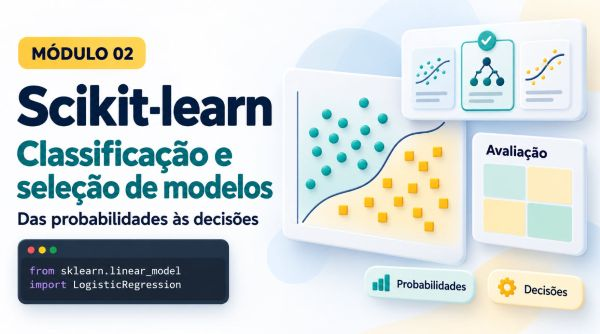

### 1.1 De regressão para classificação
| Regressão | Classificação |
|---|---|
| Alvo numérico contínuo | Alvo categórico |
| Ex.: duração de uma entrega | Ex.: entrega atrasada ou dentro do prazo |
| Previsões em horas | Classes e, em alguns modelos, probabilidades por classe |
| MAE, RMSE, R² | Matriz de confusão, precision, recall, F1, ROC-AUC e AP |

Em classificação binária usaremos `0 = dentro do prazo` e **`1 = atraso`**, a classe positiva. Positiva não significa desejável: é o evento que queremos identificar.

`predict()` devolve uma classe. `predict_proba()` devolve uma matriz com uma coluna por classe, na ordem de `classes_`. **Não assumas que a coluna 1 é sempre a classe que te interessa: consulta `classes_`.** Nem todos os classificadores disponibilizam probabilidades.

Uma probabilidade estimada e uma decisão são objetos diferentes. Para passar de uma à outra é necessário uma regra, por exemplo prever atraso se a probabilidade for pelo menos 0,5.

### 1.2 NumPy aplicado a probabilidades

O exemplo é apenas uma matriz inventada para ilustrar formas, seleção de colunas e limiares; ainda não é um modelo.

In [3]:
classes_exemplo = np.array([0,1])
probas_exemplo = np.array([[0.8,0.2],[0.35,0.65],[0.6,0.4]])
posicao_positiva = int(np.flatnonzero(classes_exemplo == 1)[0])
p_atraso_exemplo = probas_exemplo[:,posicao_positiva]
print("Forma da matriz:", probas_exemplo.shape)
print("Probabilidade da classe 1:", p_atraso_exemplo)
print("Decisão com limiar 0.5:", (p_atraso_exemplo >= 0.5).astype(int))
print("Decisão com limiar 0.3:", (p_atraso_exemplo >= 0.3).astype(int))
np.testing.assert_allclose(probas_exemplo.sum(axis=1),1.)

Forma da matriz: (3, 2)
Probabilidade da classe 1: [0.2  0.65 0.4 ]
Decisão com limiar 0.5: [0 1 0]
Decisão com limiar 0.3: [0 1 1]


**Interpretação:** Baixar o limiar pode aumentar a quantidade de alertas. Muda as classes atribuídas, não as probabilidades estimadas. Em igualdade exata com 0,5, a regra `>=` definida neste notebook pode diferir do desempate interno de `predict`.

### Exercício 1

Com classes `[1,0]` e probabilidades `[[0.7,0.3],[0.2,0.8]]`, seleciona explicitamente a coluna da classe 1 e aplica o limiar 0,4. Explica por que usar sempre `[:,1]` seria errado aqui.

Tenta antes de consultar a solução comentada no final.

In [4]:
# Exercício 1 – escreve a tua resolução aqui.


## 2. Cenário original: sinalizar entregas com risco de atraso
**Pergunta:** no momento da expedição, que envios devemos sinalizar para acompanhamento por risco de atraso?

**Unidade de observação:** um envio fictício independente. Não há linhas repetidas do mesmo cliente nem sequência temporal neste exemplo. Uma operação real exigiria verificar grupos, tempo, disponibilidade dos rótulos e mudanças de distribuição.

| Coluna | Significado | Papel |
|---|---|---|
| envio_id | Identificador fictício único | Excluído das entradas |
| distancia_km | Distância prevista | Numérica, conhecida à expedição |
| peso_kg | Peso do envio | Numérica, com algumas ausências |
| carga_percentual | Carga operacional no momento da expedição | Numérica |
| servico | normal ou expresso | Categórica, com algumas ausências |
| regiao | Norte, Centro ou Sul | Categórica |
| atraso | Resultado conhecido posteriormente: 0/1 | Alvo |

Não usaríamos duração efetiva, data efetiva de entrega ou um estado registado depois do atraso como entradas: conteriam informação futura.

Os dados são sintéticos, com um mecanismo probabilístico. Assim, duas observações parecidas podem ter resultados diferentes. Nenhum desempenho obtido deve ser interpretado como resultado numa transportadora real.

In [5]:
rng = np.random.default_rng(202)
n = 1200
distancia = rng.uniform(10,600,n)
peso = rng.gamma(2.0,3.0,n)
carga = rng.uniform(10,95,n)
servico = rng.choice(["normal","expresso"],n,p=[0.75,0.25]).astype(object)
regiao = rng.choice(["Norte","Centro","Sul"],n).astype(object)
logit_sintetico = (-5.0 + 0.004*distancia + 0.08*peso + 0.025*carga
                   - 0.8*(servico=="expresso") + 0.5*(regiao=="Sul"))
p_geradora = 1/(1+np.exp(-logit_sintetico))
y_gerado = rng.binomial(1,p_geradora)
dados = pd.DataFrame({"envio_id":[f"S{i:05d}" for i in range(n)],
    "distancia_km":distancia,"peso_kg":peso,"carga_percentual":carga,
    "servico":servico,"regiao":regiao,"atraso":y_gerado})
dados.loc[rng.choice(n,45,replace=False),"peso_kg"] = np.nan
dados.loc[rng.choice(n,28,replace=False),"servico"] = np.nan
NUMERICAS = ["distancia_km","peso_kg","carga_percentual"]
CATEGORICAS = ["servico","regiao"]
FEATURES = NUMERICAS+CATEGORICAS
X = dados[FEATURES].copy()
y = dados["atraso"].copy()
assert dados["envio_id"].is_unique
assert set(y.unique()) == {0,1}
assert "atraso" not in X.columns and "envio_id" not in X.columns
# p_geradora e logit_sintetico são apenas o mecanismo do simulador, nunca entradas do modelo.
print("Observações:",len(X),"| entradas:",X.shape[1])

Observações: 1200 | entradas: 5


### 2.1 Separação estratificada em três conjuntos
`stratify=y` preserva aproximadamente as proporções das classes. Isto ajuda a evitar subconjuntos sem a classe rara, mas não garante representatividade ou independência.

- **Treino: 60%** – ajuste, comparação e pesquisa por validação cruzada.
- **Validação: 20%** – escolha do limiar para um modelo já selecionado.
- **Teste: 20%** – avaliação final da política definida.

Escolher o melhor modelo e o melhor limiar nos mesmos resultados pode introduzir otimismo. A separação de funções reduz esse risco. Não procuramos sementes até obter uma avaliação favorável.

In [6]:
X_resto,X_teste,y_resto,y_teste = train_test_split(X,y,test_size=0.2,stratify=y,random_state=41)
X_treino,X_val,y_treino,y_val = train_test_split(X_resto,y_resto,test_size=0.25,stratify=y_resto,random_state=42)
assert len(X_treino)+len(X_val)+len(X_teste)==len(X)
for a,b in [(X_treino,X_val),(X_treino,X_teste),(X_val,X_teste)]:
    assert set(a.index).isdisjoint(b.index)
print("Treino:",X_treino.shape,"| validação:",X_val.shape,"| teste reservado:",X_teste.shape)
display(pd.DataFrame({"contagem_treino":y_treino.value_counts(),
                      "proporcao_treino":y_treino.value_counts(normalize=True)}))
display(X_treino.head())
display(X_treino.isna().sum())

Treino: (720, 5) | validação: (240, 5) | teste reservado: (240, 5)


,contagem_treino,proporcao_treino
atraso,,
0,595,0.826389
1,125,0.173611


,distancia_km,peso_kg,carga_percentual,servico,regiao
440,205.823753,3.054924,65.836118,normal,Sul
824,405.650474,2.886197,23.321793,NaN,Sul
475,491.777261,8.258402,55.935600,normal,Norte
77,271.161672,4.487177,50.823903,normal,Centro
798,251.185009,23.098878,89.901644,normal,Norte


distancia_km         0
peso_kg             24
carga_percentual     0
servico             22
regiao               0
dtype: int64

### Exercício 2

Confirma que as classes existem em treino e validação, calcula a proporção de atrasos nesses dois conjuntos e verifica que os índices não se cruzam. Não uses os alvos do teste para explorar ou escolher.

Tenta antes de consultar a solução comentada no final.

In [7]:
# Exercício 2 – escreve a tua resolução aqui.


## 3. Métricas e referência: o que significa errar?
Com classe positiva 1, a matriz de confusão de `confusion_matrix(..., labels=[0,1])` organiza **linhas observadas** e **colunas previstas**:

| | Previsto 0 | Previsto 1 |
|---|---|---|
| Observado 0 | Verdadeiro negativo (TN) | Falso positivo (FP): alerta sem atraso |
| Observado 1 | Falso negativo (FN): atraso não sinalizado | Verdadeiro positivo (TP) |

$$\mathrm{precision}=\frac{TP}{TP+FP},\qquad
\mathrm{recall}=\frac{TP}{TP+FN},\qquad
F1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$

- **Accuracy:** proporção global de previsões certas; pode esconder falhas na classe minoritária.
- **Precision:** entre os alertas emitidos, que fração corresponde a atrasos?
- **Recall/sensibilidade:** entre os atrasos ocorridos, que fração foi sinalizada?
- **F1:** média harmónica entre precision e recall; não contabiliza TN diretamente.
- **Balanced accuracy:** média do recall de cada classe, dando igual peso às classes.

Quando uma divisão é indefinida, usamos `zero_division=0` para apresentar zero sem avisos. Isso é uma convenção de relatório, não demonstração de bom desempenho.

**Custos didáticos pré-definidos:** cada FN custa 5 unidades e cada FP custa 1. São unidades de penalização inventadas, não euros ou custos observados. O objetivo posterior será minimizar `5*FN + FP` na validação. Esta simplificação assume custos constantes e aditivos.

In [8]:
CUSTO_FN=5
CUSTO_FP=1

def metricas_decisao(y_real,y_previsto):
    tn,fp,fn,tp = confusion_matrix(y_real,y_previsto,labels=[0,1]).ravel()
    return {"accuracy":accuracy_score(y_real,y_previsto),
            "balanced_accuracy":balanced_accuracy_score(y_real,y_previsto),
            "precision":precision_score(y_real,y_previsto,zero_division=0),
            "recall":recall_score(y_real,y_previsto,zero_division=0),
            "f1":f1_score(y_real,y_previsto,zero_division=0),
            "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),
            "alertas":int(fp+tp),"custo":int(CUSTO_FN*fn+CUSTO_FP*fp)}

y_exemplo=np.array([0,0,0,1,1,1])
prev_exemplo=np.array([0,1,0,1,0,1])
display(pd.Series(metricas_decisao(y_exemplo,prev_exemplo)))
assert confusion_matrix(y_exemplo,prev_exemplo,labels=[0,1]).tolist()==[[2,1],[1,2]]

accuracy             0.666667
balanced_accuracy    0.666667
precision            0.666667
recall               0.666667
f1                   0.666667
TN                   2.000000
FP                   1.000000
FN                   1.000000
TP                   2.000000
alertas              3.000000
custo                6.000000
dtype: float64

### 3.1 Uma referência que aprende as proporções

`DummyClassifier(strategy="prior")` aprende as frequências de classe no treino; `predict` escolhe a classe maioritária e `predict_proba` devolve as proporções aprendidas. É uma referência, não um modelo útil por definição.

In [9]:
referencia=DummyClassifier(strategy="prior").fit(X_treino,y_treino)
prev_referencia_treino=referencia.predict(X_treino)
display(pd.Series(metricas_decisao(y_treino,prev_referencia_treino)))
print("Proporções aprendidas:",referencia.class_prior_)
print("Previsões positivas:",(prev_referencia_treino==1).sum())

accuracy               0.826389
balanced_accuracy      0.500000
precision              0.000000
recall                 0.000000
f1                     0.000000
TN                   595.000000
FP                     0.000000
FN                   125.000000
TP                     0.000000
alertas                0.000000
custo                625.000000
dtype: float64

Proporções aprendidas: [0.82638889 0.17361111]
Previsões positivas: 0


**Interpretação:** Uma accuracy alta pode coexistir com recall zero dos atrasos. Estes números são no treino; a comparação de modelos será feita por validação cruzada e a avaliação final ficará para o teste.

### Exercício 3

Para observado `[0,0,1,1,1]` e previsto `[0,1,1,0,1]`, identifica TN, FP, FN e TP. Calcula precision, recall, F1 e custo. Explica a diferença entre precision e recall.

Tenta antes de consultar a solução comentada no final.

In [10]:
# Exercício 3 – escreve a tua resolução aqui.


## 4. Preparar variáveis numéricas e categóricas
Não atribuiremos códigos arbitrários Norte=0, Centro=1, Sul=2 como se existisse uma distância natural entre regiões. `OneHotEncoder` cria indicadores de pertença a categorias.

- **Numéricas:** imputação pela mediana e padronização.
- **Categóricas:** imputação pela moda e codificação one-hot.
- **ColumnTransformer:** aplica cada sequência às colunas correspondentes.
- **Pipeline:** reúne preparação e classificador, para que a validação cruzada reaprenda as transformações em cada treino de fold.

O kNN e a regressão logística beneficiam da atenção às escalas. As árvores não exigem geralmente padronização; mantemos a mesma preparação nesta comparação introdutória para simplificar o percurso. A ponderação de categorias e variáveis continua a influenciar distâncias no kNN.

In [11]:
def criar_preparador():
    numericas=Pipeline([("imputar",SimpleImputer(strategy="median")),("escalar",StandardScaler())])
    categoricas=Pipeline([("imputar",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
    return ColumnTransformer([("num",numericas,NUMERICAS),("cat",categoricas,CATEGORICAS)],
                             remainder="drop",verbose_feature_names_out=True)

def criar_pipeline(classificador):
    return Pipeline([("preparar",criar_preparador()),("modelo",classificador)])

preparador_demo=criar_preparador().fit(X_treino)
matriz_treino=preparador_demo.transform(X_treino)
nomes_transformados=preparador_demo.get_feature_names_out()
display(pd.DataFrame(matriz_treino[:5],columns=nomes_transformados,index=X_treino.head().index))
print("Forma antes/depois:",X_treino.shape,matriz_treino.shape)
assert np.isfinite(matriz_treino).all()

,num__distancia_km,num__peso_kg,num__carga_percentual,cat__servico_expresso,cat__servico_normal,cat__regiao_Centro,cat__regiao_Norte,cat__regiao_Sul
440,-0.608004,-0.652636,0.574254,0.0,1.0,0.0,0.0,1.0
824,0.605064,-0.692369,-1.185244,0.0,1.0,0.0,0.0,1.0
475,1.127905,0.572714,0.164511,0.0,1.0,0.0,1.0,0.0
77,-0.211364,-0.315360,-0.047042,0.0,1.0,1.0,0.0,0.0
798,-0.332634,4.067451,1.570230,0.0,1.0,0.0,1.0,0.0


Forma antes/depois: (720, 5) (720, 8)


### 4.1 Categorias novas e verificação das estatísticas

`handle_unknown="ignore"` permite transformar uma categoria não vista; os indicadores desse campo ficam todos a zero. Isto evita uma falha técnica, mas não garante uma previsão fiável para uma população nova.

In [12]:
novo_tipo=X_treino.head(1).copy()
novo_tipo.loc[:,"regiao"]="Ilhas"
novo_transformado=preparador_demo.transform(novo_tipo)
colunas_regiao=np.array(["cat__regiao_" in nome for nome in nomes_transformados])
assert np.all(novo_transformado[:,colunas_regiao]==0)
print("Indicadores de região desconhecida:",novo_transformado[:,colunas_regiao])
medianas=preparador_demo.named_transformers_["num"].named_steps["imputar"].statistics_
np.testing.assert_allclose(medianas,X_treino[NUMERICAS].median().to_numpy())
print("Medianas aprendidas só no treino:",medianas)

Indicadores de região desconhecida: [[0. 0. 0.]]
Medianas aprendidas só no treino: [309.61387179   4.87017457  53.5823502 ]


**Interpretação:** Usamos saída densa para facilitar a inspeção de uma pequena tabela. Em dados com muitas categorias, a saída esparsa pode poupar memória. Não ajustes um codificador separado nos dados novos: as colunas deixariam de estar necessariamente alinhadas.

### Exercício 4

Obtém os nomes das colunas transformadas e verifica que `envio_id` e `atraso` não aparecem. Confirma que a transformação da validação tem o mesmo número de colunas, sem ajustar o preparador na validação.

Tenta antes de consultar a solução comentada no final.

In [13]:
# Exercício 4 – escreve a tua resolução aqui.


## 5. Três famílias de classificadores
### 5.1 Regressão logística
Apesar do nome, é um método de **classificação**. No caso binário, transforma uma combinação linear das entradas numa probabilidade através da função logística:

$$p(y=1\mid x)=\frac{1}{1+\exp(-z)},\qquad z=\beta_0+\beta^Tx.$$

`C` controla inversamente a intensidade da regularização: valores menores correspondem a maior regularização. Os coeficientes atuam nos log-odds, não são diretamente variações de probabilidade em pontos percentuais.–

### 5.2 k-vizinhos mais próximos – kNN
Classifica com base nas observações próximas. `n_neighbors` define quantos vizinhos são consultados; `weights="distance"` dá mais peso aos próximos. É sensível a escalas, variáveis irrelevantes e escolhas da distância. Prever pode exigir trabalho sobre muitas observações de treino.

### 5.3 Árvore de decisão
Aprende divisões do espaço das entradas. `max_depth` e `min_samples_leaf` limitam a complexidade. Árvores profundas podem sobreajustar; pequenas alterações nos dados podem mudar a estrutura. As probabilidades das folhas não são automaticamente bem calibradas.

In [14]:
modelos_base={
    "logistica":criar_pipeline(LogisticRegression(max_iter=2000)),
    "knn":criar_pipeline(KNeighborsClassifier(n_neighbors=15)),
    "arvore":criar_pipeline(DecisionTreeClassifier(max_depth=4,min_samples_leaf=15,random_state=10))
}
logistica_demo=clone(modelos_base["logistica"]).fit(X_treino,y_treino)

def probabilidade_positiva(modelo,X_entrada):
    classes=np.asarray(modelo.classes_)
    pos=np.flatnonzero(classes==1)
    if len(pos)!=1:
        raise ValueError("Esperada classe positiva 1 exatamente uma vez.")
    return modelo.predict_proba(X_entrada)[:,int(pos[0])]

p_demo=probabilidade_positiva(logistica_demo,X_treino.head())
print("Classes:",logistica_demo.classes_)
print("Probabilidades:",p_demo)
print("Classes previstas:",logistica_demo.predict(X_treino.head()))
print("Forma predict_proba:",logistica_demo.predict_proba(X_treino.head()).shape)
assert np.all((p_demo>=0)&(p_demo<=1))

Classes:

 [0 1]
Probabilidades: [0.17549977 0.14605597 0.22942492 0.124781   0.46893177]
Classes previstas: [0 0 0 0 0]
Forma predict_proba: (5, 2)


### Exercício 5

Ajusta o kNN só no treino. Nas primeiras três linhas do treino, mostra `classes_`, a matriz de probabilidades, a coluna da classe positiva e as classes previstas. Não interpretes o desempenho nas próprias linhas como generalização.

Tenta antes de consultar a solução comentada no final.

In [15]:
# Exercício 5 – escreve a tua resolução aqui.


## 6. Comparar com validação cruzada estratificada
Usamos os mesmos cinco folds para todas as pipelines. `StratifiedKFold` procura manter proporções de classe semelhantes. A preparação é reaprendida dentro do treino de cada fold.

**Critério principal pré-definido:** maior **average precision (AP)** na validação cruzada. AP resume precision e recall ao variar o limiar e é útil para avaliar a ordenação da classe positiva. Também reportaremos ROC-AUC e métricas de classes. Uma métrica não substitui a análise do custo e da capacidade de resposta.

AP não é a precision num limiar específico nem é, em geral, a área trapezoidal calculada sob uma curva precision–recall. A AP de scores constantes corresponde à prevalência da classe positiva no conjunto avaliado. O seu valor depende da composição da população.

Os campos `test_*` da API abaixo referem-se às validações internas dos folds, **não ao teste reservado**. A variação entre folds não é automaticamente um intervalo de confiança.

In [16]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=17)
SCORING={"ap":"average_precision","roc":"roc_auc","recall":"recall",
         "f1":"f1","balanced":"balanced_accuracy"}
comparacao_cv=[]
for nome,modelo in {"referencia":DummyClassifier(strategy="prior"),**modelos_base}.items():
    resultado=cross_validate(modelo,X_treino,y_treino,cv=cv,scoring=SCORING,
                              n_jobs=1,error_score="raise")
    comparacao_cv.append({"modelo":nome,"AP_cv":resultado["test_ap"].mean(),
        "AP_desvio_folds":resultado["test_ap"].std(ddof=1),
        "ROC_AUC_cv":resultado["test_roc"].mean(),"recall_cv":resultado["test_recall"].mean(),
        "F1_cv":resultado["test_f1"].mean(),"balanced_accuracy_cv":resultado["test_balanced"].mean()})
tabela_cv=pd.DataFrame(comparacao_cv).set_index("modelo").sort_values("AP_cv",ascending=False)
display(tabela_cv)

,AP_cv,AP_desvio_folds,ROC_AUC_cv,recall_cv,F1_cv,balanced_accuracy_cv
modelo,,,,,,
logistica,0.341794,0.062845,0.685244,0.048,0.088400,0.519798
knn,0.246604,0.048483,0.612168,0.000,0.000000,0.495798
arvore,0.226933,0.025993,0.580807,0.064,0.093948,0.506790
referencia,0.173611,0.000000,0.500000,0.000,0.000000,0.500000


### 6.1 Confirmar separação e aprendizagem por fold

Os índices devolvidos pelo splitter são posições; usamos `iloc`. O teste abaixo confirma que a mediana aprendida num fold vem apenas do respetivo treino.

In [17]:
idx_tr,idx_va=next(cv.split(X_treino,y_treino))
assert set(idx_tr).isdisjoint(idx_va)
assert set(y_treino.iloc[idx_tr].unique())=={0,1}
assert set(y_treino.iloc[idx_va].unique())=={0,1}
modelo_fold=clone(modelos_base["logistica"]).fit(X_treino.iloc[idx_tr],y_treino.iloc[idx_tr])
medianas_fold=(modelo_fold.named_steps["preparar"].named_transformers_["num"]
               .named_steps["imputar"].statistics_)
np.testing.assert_allclose(medianas_fold,X_treino.iloc[idx_tr][NUMERICAS].median().to_numpy())
print("Proporção positiva no treino do fold:",y_treino.iloc[idx_tr].mean())
print("Proporção positiva na validação do fold:",y_treino.iloc[idx_va].mean())

Proporção positiva no treino do fold: 0.1736111111111111
Proporção positiva na validação do fold: 0.1736111111111111


### Exercício 6

Usa `cross_validate` com a pipeline logística e o mesmo `cv` para obter AP por fold. Apresenta média e desvio e explica por que não devemos preparar o treino inteiro antes da validação cruzada.

Tenta antes de consultar a solução comentada no final.

In [18]:
# Exercício 6 – escreve a tua resolução aqui.


## 7. Seleção de hiperparâmetros e família
`GridSearchCV` percorre a grelha declarada. A sintaxe `modelo__C` aponta para o parâmetro `C` do classificador dentro da pipeline.

As três famílias são comparadas dentro da mesma pesquisa, com os mesmos folds e a mesma métrica principal. Incluímos uma referência na grelha para permitir que uma regra simples seja selecionada se as alternativas não acrescentarem valor.

`class_weight="balanced"` altera o peso das classes na função de ajuste; **não é o mesmo que escolher um limiar**. Pode alterar as probabilidades e a sua calibração. Nunca calculamos pesos usando os alvos do teste.

O score da configuração vencedora participou na seleção e pode ser otimista. A validação será usada para o limiar e o teste para a avaliação independente final.

In [19]:
grelha_parametros=[
    {"modelo":[DummyClassifier(strategy="prior")]},
    {"modelo":[LogisticRegression(max_iter=2000)],"modelo__C":[0.1,1.,10.],
     "modelo__class_weight":[None,"balanced"]},
    {"modelo":[KNeighborsClassifier()],"modelo__n_neighbors":[9,25],
     "modelo__weights":["uniform","distance"]},
    {"modelo":[DecisionTreeClassifier(random_state=10)],"modelo__max_depth":[3,6],
     "modelo__min_samples_leaf":[10,30]}
]
pesquisa=GridSearchCV(criar_pipeline(LogisticRegression(max_iter=2000)),grelha_parametros,
    scoring={"ap":"average_precision","roc":"roc_auc","f1":"f1"},refit="ap",
    cv=cv,n_jobs=1,error_score="raise",return_train_score=True)
pesquisa.fit(X_treino,y_treino)
cv_resultados=pd.DataFrame(pesquisa.cv_results_)
ranking=pd.DataFrame({"configuracao":cv_resultados["params"].map(str),
                      "AP_validacao_media":cv_resultados["mean_test_ap"],
                      "AP_desvio":cv_resultados["std_test_ap"],
                      "AP_ajuste_media":cv_resultados["mean_train_ap"],
                      "ROC_AUC_validacao_media":cv_resultados["mean_test_roc"]}).sort_values("AP_validacao_media",ascending=False)
display(ranking.head(8))
modelo_escolhido=pesquisa.best_estimator_
print("Melhor configuração:",pesquisa.best_params_)
print("Melhor AP CV:",pesquisa.best_score_)
print("O modelo foi reajustado apenas no treino de 60%.")

,configuracao,AP_validacao_media,AP_desvio,AP_ajuste_media,ROC_AUC_validacao_media
1,"{'modelo': LogisticRegression(max_iter=2000), ...",0.342650,0.054231,0.345505,0.686790
2,"{'modelo': LogisticRegression(max_iter=2000), ...",0.342620,0.051431,0.342381,0.685445
3,"{'modelo': LogisticRegression(max_iter=2000), ...",0.341794,0.056211,0.348373,0.685244
4,"{'modelo': LogisticRegression(max_iter=2000), ...",0.341229,0.048093,0.341595,0.683294
5,"{'modelo': LogisticRegression(max_iter=2000), ...",0.341063,0.056776,0.348182,0.684571
6,"{'modelo': LogisticRegression(max_iter=2000), ...",0.339955,0.047224,0.341510,0.682891
10,"{'modelo': KNeighborsClassifier(), 'modelo__n_...",0.284616,0.036521,1.000000,0.625210
9,"{'modelo': KNeighborsClassifier(), 'modelo__n_...",0.279241,0.046278,0.319268,0.635395


Melhor configuração: {'modelo': LogisticRegression(max_iter=2000), 'modelo__C': 0.1, 'modelo__class_weight': None}
Melhor AP CV: 0.34264981183637044
O modelo foi reajustado apenas no treino de 60%.


### 7.1 Pesquisa aleatória: demonstração alternativa

`RandomizedSearchCV` amostra configurações de listas ou distribuições. Nesta demonstração usa três valores escolhidos de uma lista de seis. O orçamento pode ser útil quando uma grelha seria muito extensa. Não adicionaremos esta pesquisa à seleção já definida.

In [20]:
pesquisa_aleatoria=RandomizedSearchCV(
    criar_pipeline(LogisticRegression(max_iter=2000)),
    param_distributions={"modelo__C":np.logspace(-3,2,6)},n_iter=3,
    scoring="average_precision",cv=cv,refit=True,random_state=31,n_jobs=1,error_score="raise")
pesquisa_aleatoria.fit(X_treino,y_treino)
print("Configurações sorteadas:",pesquisa_aleatoria.cv_results_["params"])
print("Melhor AP nesta demonstração:",pesquisa_aleatoria.best_score_)
print("Mantemos como modelo principal a seleção da pesquisa em grelha.")

Configurações sorteadas: [{'modelo__C': np.float64(10.0)}, {'modelo__C': np.float64(0.01)}, {'modelo__C': np.float64(1.0)}]
Melhor AP nesta demonstração: 0.3417940637256645
Mantemos como modelo principal a seleção da pesquisa em grelha.


### Exercício 7

Lê o ranking da pesquisa: identifica a configuração vencedora e compara AP de ajuste e validação. Explica por que a melhor AP de treino não define a vencedora e por que `C` menor não significa menor regularização.

Tenta antes de consultar a solução comentada no final.

In [21]:
# Exercício 7 – escreve a tua resolução aqui.


## 8. Probabilidades e avaliação de ordenação
O modelo está selecionado. Vamos agora abrir a **validação**, sem reajustar o modelo, para analisar probabilidades e escolher a política de alerta.

- **ROC:** compara taxa de verdadeiros positivos e taxa de falsos positivos ao variar o limiar. AUC resume a capacidade de ordenação; não é uma accuracy nem garante bom desempenho operacional com poucos positivos.
- **Precision–recall:** mostra a troca entre recall e precision, com foco nos positivos. Usaremos AP como resumo.
- **Brier score:** erro quadrático entre probabilidades e resultado 0/1; menor é melhor. Mistura componentes de desempenho e não mede apenas calibração.
- **Log loss:** penaliza atribuir probabilidades muito baixas aos resultados que ocorrem; menor é melhor.

Uma estimativa de 0,8 não garante o evento naquele caso. Boa ordenação não implica probabilidades bem calibradas. A calibração formal e a validação temporal ficam para aprofundamento posterior.

AP          0.327976
ROC_AUC     0.750705
Brier       0.130509
log_loss    0.412725
Name: validacao, dtype: float64

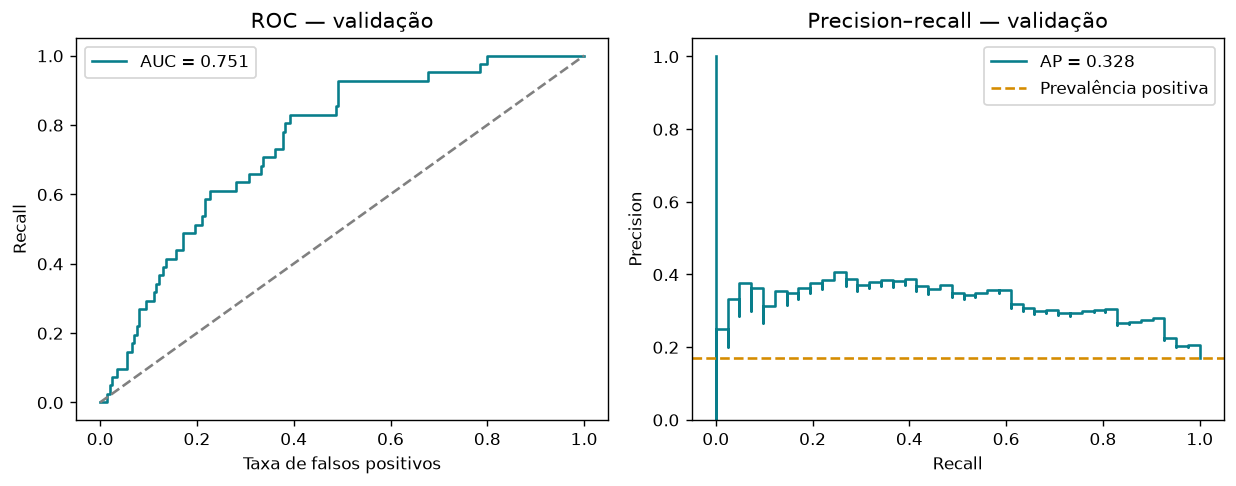

In [22]:
p_val=probabilidade_positiva(modelo_escolhido,X_val)
assert p_val.shape==(len(X_val),) and np.isfinite(p_val).all()
assert ((p_val>=0)&(p_val<=1)).all()
metricas_prob_val={"AP":average_precision_score(y_val,p_val),
    "ROC_AUC":roc_auc_score(y_val,p_val),"Brier":brier_score_loss(y_val,p_val),
    "log_loss":log_loss(y_val,np.column_stack([1-p_val,p_val]),labels=[0,1])}
display(pd.Series(metricas_prob_val,name="validacao"))
fpr,tpr,_=roc_curve(y_val,p_val)
precision_curva,recall_curva,_=precision_recall_curve(y_val,p_val)
fig,eixos=plt.subplots(1,2,figsize=(10,4))
eixos[0].plot(fpr,tpr,color="#087e8b",label=f"AUC = {metricas_prob_val['ROC_AUC']:.3f}")
eixos[0].plot([0,1],[0,1],"--",color="grey")
eixos[0].set(xlabel="Taxa de falsos positivos",ylabel="Recall",title="ROC — validação")
eixos[0].legend()
eixos[1].step(recall_curva,precision_curva,where="post",color="#087e8b",label=f"AP = {metricas_prob_val['AP']:.3f}")
eixos[1].axhline(y_val.mean(),ls="--",color="#d58c00",label="Prevalência positiva")
eixos[1].set(xlabel="Recall",ylabel="Precision",title="Precision–recall — validação",ylim=(0,1.05))
eixos[1].legend();fig.tight_layout();mostrar_figura(fig)

### 8.1 Probabilidades e confiança: inspeção por intervalos

Agrupamos scores para comparar a média estimada e a frequência observada. Intervalos pequenos podem ter muito poucos casos; não reajustamos nem calibramos o modelo com este gráfico.

In [23]:
inspecao=pd.DataFrame({"p":p_val,"observado":y_val.to_numpy()})
inspecao["intervalo"]=pd.cut(inspecao["p"],bins=np.linspace(0,1,6),include_lowest=True)
por_intervalo=(inspecao.groupby("intervalo",observed=True)
               .agg(casos=("observado","size"),prob_media=("p","mean"),taxa_observada=("observado","mean")))
display(por_intervalo)
print("As contagens são necessárias para interpretar diferenças entre média prevista e frequência observada.")

,casos,prob_media,taxa_observada
intervalo,,,
"(-0.001, 0.2]",179,0.119686,0.111732
"(0.2, 0.4]",56,0.272256,0.357143
"(0.4, 0.6]",5,0.474454,0.200000


As contagens são necessárias para interpretar diferenças entre média prevista e frequência observada.


### Exercício 8

Mostra as formas de `predict_proba(X_val)` e de `p_val`. Usa NumPy para contar quantas probabilidades de atraso são pelo menos 0,5 e pelo menos 0,2. Confirma que as probabilidades não mudam quando só mudas o limiar.

Tenta antes de consultar a solução comentada no final.

In [24]:
# Exercício 8 – escreve a tua resolução aqui.


## 9. Escolher um limiar com objetivo explícito
Para cada limiar candidato, calculamos custo = `5*FN + FP`, com os pesos definidos antes da seleção. Escolhemos o menor custo na validação; em empate, preferimos menos falsos positivos e depois o limiar mais alto. Incluímos políticas extremas: alertar todos e não alertar ninguém.

A escolha é empírica numa validação finita e pode ser instável. Não garante o menor custo futuro. Alterar os custos, a prevalência ou a capacidade de acompanhamento pode mudar a política adequada.

**Distinção importante:** AP escolheu a ordenação/modelo na pesquisa; o custo escolhe agora uma decisão. Selecionar por AP não garante o melhor custo possível entre todas as famílias. Avaliar conjuntamente família e política exigiria um procedimento de validação mais elaborado.

Não usamos as linhas de treino para escolher o limiar e não o reajustamos depois no teste.

In [25]:
limiares=np.r_[np.arange(0.,1.0,0.05),1.01]
linhas_limiares=[]
for limiar in limiares:
    previsoes=(p_val>=limiar).astype(int)
    linhas_limiares.append({"limiar":float(limiar),**metricas_decisao(y_val,previsoes)})
tabela_limiares=pd.DataFrame(linhas_limiares)
politica=(tabela_limiares.sort_values(["custo","FP","limiar"],ascending=[True,True,False]).iloc[0])
limiar_escolhido=float(politica["limiar"])
display(tabela_limiares.sort_values(["custo","FP"]).head(8))
print("Limiar escolhido:",limiar_escolhido)
print("1.01 representa a política sem alertas, porque probabilidades não ultrapassam 1.")
assert np.isclose(politica["custo"],CUSTO_FN*politica["FN"]+CUSTO_FP*politica["FP"])

,limiar,accuracy,balanced_accuracy,precision,recall,f1,TN,FP,FN,TP,alertas,custo
3,0.15,0.637500,0.713629,0.298246,0.829268,0.438710,119,80,7,34,114,115
4,0.20,0.750000,0.655595,0.344262,0.512195,0.411765,159,40,20,21,61,140
2,0.10,0.395833,0.616313,0.214286,0.951220,0.349776,56,143,2,39,182,153
5,0.25,0.791667,0.612943,0.378378,0.341463,0.358974,176,23,27,14,37,158
6,0.30,0.804167,0.562385,0.363636,0.195122,0.253968,185,14,33,8,22,179
1,0.05,0.216667,0.527638,0.179039,1.000000,0.303704,11,188,0,41,229,188
7,0.35,0.812500,0.528680,0.333333,0.097561,0.150943,191,8,37,4,12,193
0,0.00,0.170833,0.500000,0.170833,1.000000,0.291815,0,199,0,41,240,199


Limiar escolhido: 0.15000000000000002
1.01 representa a política sem alertas, porque probabilidades não ultrapassam 1.


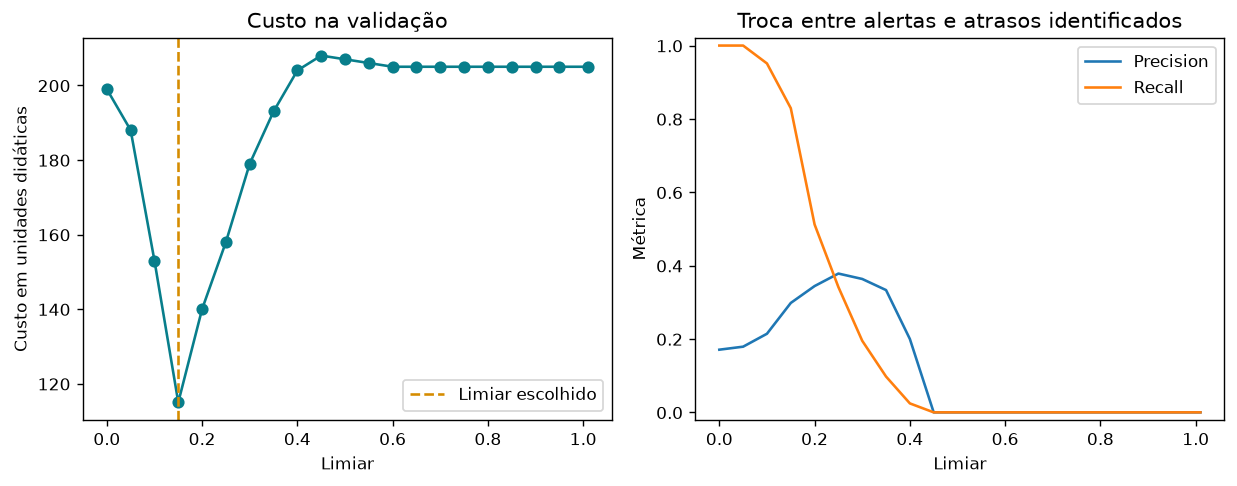

A política escolhida altera apenas as classes atribuídas; não altera a curva ROC nem a AP do score.


In [26]:
fig,eixos=plt.subplots(1,2,figsize=(10,4))
eixos[0].plot(tabela_limiares["limiar"],tabela_limiares["custo"],marker="o",color="#087e8b")
eixos[0].axvline(limiar_escolhido,ls="--",color="#d58c00",label="Limiar escolhido")
eixos[0].set(xlabel="Limiar",ylabel="Custo em unidades didáticas",title="Custo na validação");eixos[0].legend()
eixos[1].plot(tabela_limiares["limiar"],tabela_limiares["precision"],label="Precision")
eixos[1].plot(tabela_limiares["limiar"],tabela_limiares["recall"],label="Recall")
eixos[1].set(xlabel="Limiar",ylabel="Métrica",title="Troca entre alertas e atrasos identificados",ylim=(-0.02,1.02))
eixos[1].legend();fig.tight_layout();mostrar_figura(fig)
print("A política escolhida altera apenas as classes atribuídas; não altera a curva ROC nem a AP do score.")

### Exercício 9

Na validação, compara as contagens de FP e FN para limiares 0,2 e 0,5. Explica os custos da decisão sem alterar o limiar final escolhido. Não uses o teste para escolher outro limiar.

Tenta antes de consultar a solução comentada no final.

In [27]:
# Exercício 9 – escreve a tua resolução aqui.


## 10. Avaliação final da política no teste reservado
Só agora consultamos os alvos do teste. Vamos reportar a referência, a regra de limiar 0,5 e a política escolhida previamente. São comparações descritivas planeadas: **não escolhemos outra regra depois de ver os resultados**.

O modelo mantém o ajuste nos 60% de treino. Reajustá-lo agora em treino + validação mudaria potencialmente os scores e invalidaria a correspondência direta com o limiar selecionado. Para usar mais dados e afinar limiares por reamostragem, seria necessário outro protocolo, por exemplo validação interna específica de limiar.

,accuracy,balanced_accuracy,precision,recall,f1,TN,FP,FN,TP,alertas,custo
referencia,0.829167,0.500000,0.000000,0.000000,0.000000,199.0,0.0,41.0,0.0,0.0,205.0
modelo_limiar_05,0.825000,0.497487,0.000000,0.000000,0.000000,198.0,1.0,41.0,0.0,1.0,206.0
politica_escolhida,0.595833,0.678821,0.270492,0.804878,0.404908,110.0,89.0,8.0,33.0,122.0,129.0


,AP,ROC_AUC
referencia,0.170833,0.500000
modelo_escolhido,0.342682,0.723986


                 precision    recall  f1-score   support

Dentro do prazo       0.93      0.55      0.69       199
         Atraso       0.27      0.80      0.40        41

       accuracy                           0.60       240
      macro avg       0.60      0.68      0.55       240
   weighted avg       0.82      0.60      0.64       240



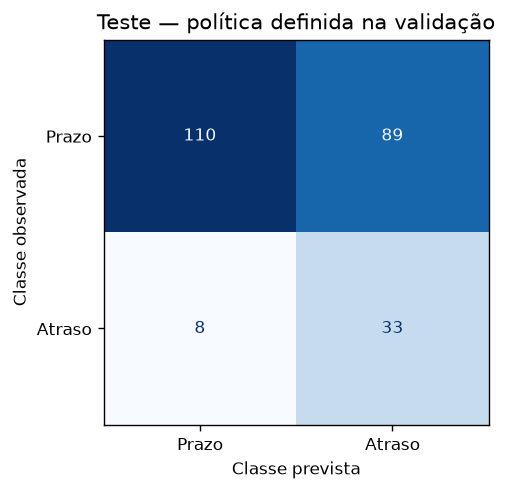

In [28]:
p_teste=probabilidade_positiva(modelo_escolhido,X_teste)
p_teste_base=probabilidade_positiva(referencia,X_teste)
prev_teste=(p_teste>=limiar_escolhido).astype(int)
prev_teste_05=(p_teste>=0.5).astype(int)
prev_teste_base=referencia.predict(X_teste)
metricas_teste=pd.DataFrame({
    "referencia":metricas_decisao(y_teste,prev_teste_base),
    "modelo_limiar_05":metricas_decisao(y_teste,prev_teste_05),
    "politica_escolhida":metricas_decisao(y_teste,prev_teste)
}).T
display(metricas_teste)
ranking_teste=pd.DataFrame({
    "referencia":{"AP":average_precision_score(y_teste,p_teste_base),"ROC_AUC":roc_auc_score(y_teste,p_teste_base)},
    "modelo_escolhido":{"AP":average_precision_score(y_teste,p_teste),"ROC_AUC":roc_auc_score(y_teste,p_teste)}
}).T
display(ranking_teste)
print(classification_report(y_teste,prev_teste,labels=[0,1],
                            target_names=["Dentro do prazo","Atraso"],zero_division=0))
assert len(prev_teste)==len(y_teste)
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_teste,prev_teste,labels=[0,1],
    display_labels=["Prazo","Atraso"],cmap="Blues",colorbar=False,ax=ax)
ax.set(xlabel="Classe prevista",ylabel="Classe observada",title="Teste — política definida na validação")
mostrar_figura(fig)

Se a política tiver custo maior no teste do que a alternativa, reporta o resultado: não mudes de limiar usando esse teste. Uma validação pequena, incerteza e diferenças de distribuição podem afetar a transferência.

O suporte apresentado em `classification_report` é a contagem de observações de cada classe. Macro é uma média sem ponderação por tamanho de classe; weighted pondera pelo suporte e pode ocultar um resultado fraco na classe rara. A linha accuracy representa o acerto global.

A investigação dos erros pode orientar um novo estudo. Depois de reutilizar o teste para tomar decisões, seria preciso outra avaliação independente das mudanças.

### Exercício 10

Sem reajustar o modelo, confirma TN+FP+FN+TP = número de linhas de teste. Reporta o número de alertas e a proporção de atrasos identificados pela política, explicando o denominador de cada métrica.

Tenta antes de consultar a solução comentada no final.

In [29]:
# Exercício 10 – escreve a tua resolução aqui.


## 11. Miniprojeto: aplicar a política e criar uma entrega verificável
Uma política de classificação inclui **preparação + modelo + ordem das classes + limiar + significado do alerta**. Guardar apenas o nome do classificador não documenta a decisão.

Vamos receber três envios fictícios, validar a estrutura, calcular scores e aplicar o limiar fixado. Categorias desconhecidas são aceites tecnicamente pelo codificador; isso deve ser sinalizado e acompanhado numa aplicação real.

In [30]:
def validar_entradas(df):
    if df.columns.tolist()!=FEATURES:
        raise ValueError(f"Esperadas colunas nesta ordem: {FEATURES}")
    if not all(pd.api.types.is_numeric_dtype(df[c]) for c in NUMERICAS):
        raise ValueError("As entradas numéricas devem ter tipos numéricos.")
    numeros=df[NUMERICAS].to_numpy(dtype=float)
    if np.isinf(numeros).any():
        raise ValueError("Infinitos não são aceites; NaN será tratado pela pipeline.")
    if (df["distancia_km"].dropna()<=0).any() or (df["peso_kg"].dropna()<=0).any():
        raise ValueError("Distância e peso conhecidos devem ser positivos.")
    if not df["carga_percentual"].dropna().between(0,100).all():
        raise ValueError("Carga operacional fora de [0,100].")
    return df

novos=pd.DataFrame({"distancia_km":[80.,450.,300.],"peso_kg":[2.,12.,np.nan],
    "carga_percentual":[30.,90.,75.],"servico":["expresso","normal",np.nan],
    "regiao":["Norte","Sul","Ilhas"]})
novos=validar_entradas(novos)
p_novos=probabilidade_positiva(modelo_escolhido,novos)
saida_novos=novos.assign(probabilidade_atraso=p_novos,
                         alerta_acompanhamento=(p_novos>=limiar_escolhido).astype(int))
display(saida_novos)
print("Região Ilhas não existia no treino: a compatibilidade técnica não prova adequação à nova região.")
print("Alerta é uma recomendação de acompanhamento, não uma certeza de atraso.")

,distancia_km,peso_kg,carga_percentual,servico,regiao,probabilidade_atraso,alerta_acompanhamento
0,80.0,2.0,30.0,expresso,Norte,0.034552,0
1,450.0,12.0,90.0,normal,Sul,0.510568,1
2,300.0,NaN,75.0,NaN,Ilhas,0.203588,1


Região Ilhas não existia no treino: a compatibilidade técnica não prova adequação à nova região.
Alerta é uma recomendação de acompanhamento, não uma certeza de atraso.


In [31]:
relatorio_teste=X_teste.copy()
relatorio_teste["envio_id"]=dados.loc[X_teste.index,"envio_id"]
relatorio_teste["observado"]=y_teste
relatorio_teste["p_atraso"]=p_teste
relatorio_teste["alerta"]=prev_teste
metricas_teste.to_csv(PASTA/"metricas_teste.csv",sep=";",decimal=",",encoding="utf-8-sig",index_label="politica")
relatorio_teste.to_csv(PASTA/"previsoes_teste.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
saida_novos.to_csv(PASTA/"novos_envios.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
metadados={"origem":"Dados sintéticos originais, semente 202","versoes":VERSOES,
    "features":FEATURES,"classe_positiva":1,"significado_positivo":"Atraso",
    "classes_modelo":modelo_escolhido.classes_.tolist(),
    "particoes":{"treino":len(X_treino),"validacao":len(X_val),"teste":len(X_teste)},
    "escolha_modelo":"Maior AP média CV estratificada em 5 folds no treino",
    "hiperparametros":{k:str(v) for k,v in pesquisa.best_params_.items()},
    "limiar":limiar_escolhido,"escolha_limiar":"Menor custo na validação; empate: menos FP e maior limiar",
    "custos_didaticos":{"FN":CUSTO_FN,"FP":CUSTO_FP},
    "refit_apos_limiar":False,"metricas_teste":metricas_teste.to_dict(orient="index"),
    "limitacoes":["Dados sintéticos","Custos inventados","Sem validação temporal externa",
                  "Sem calibração formal","Não é um sistema operacional"]}
(PASTA/"metadados.json").write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding="utf-8")
lido=pd.read_csv(PASTA/"previsoes_teste.csv",sep=";",decimal=",")
assert lido["envio_id"].tolist()==relatorio_teste["envio_id"].tolist()
np.testing.assert_allclose(lido["p_atraso"].to_numpy(),p_teste)
print("Exportação e reimportação verificadas.")

Exportação e reimportação verificadas.


### Checklist de adaptação
1. Define o evento positivo e o momento da previsão.
2. Confirma a disponibilidade das entradas e dos rótulos.
3. Separa dados respeitando tempo, grupos ou independência.
4. Escolhe métricas e custos antes de procurar resultados favoráveis.
5. Aprende as transformações dentro da pipeline e dos folds.
6. Escolhe a configuração sem consultar o teste.
7. Ajusta a política numa validação independente do ajuste do modelo.
8. Reporta a avaliação final e a quantidade de alertas, incluindo limites.
9. Documenta a versão das bibliotecas, classes, limiar e regras.

**Autoavaliação:** 0–2 pontos por item: ausente, parcial, demonstrado e explicado. Total: 18 pontos. Na prática, qualidade dos rótulos, custos e capacidade operacional podem ser mais importantes do que pequenas diferenças entre algoritmos.

### Exercício 11

Cria um novo DataFrame com duas linhas válidas. Aplica `validar_entradas`, a pipeline e o limiar fixado. Guarda ID fictício, score e alerta num CSV e confirma a reimportação. Não ajustes o modelo nos novos dados.

Tenta antes de consultar a solução comentada no final.

In [32]:
# Exercício 11 – escreve a tua resolução aqui.


## 12. Extensão opcional: classificação multiclasse
O problema principal tem duas classes. Para três ou mais classes, `predict_proba` devolve uma coluna por classe e o resultado de `predict` seleciona uma classe segundo o classificador. Um único limiar binário não descreve automaticamente uma política multiclasse.

**Exemplo independente:** três grupos sintéticos de observações em duas variáveis. Não usamos nem alteramos as partições do projeto de atrasos.

- **Macro F1:** média dos F1 de cada classe, com igual peso por classe.
- **Weighted F1:** média ponderada pelo número de observações de cada classe.
- **Micro:** agrega contagens globalmente; no caso multiclasse de rótulo único, com todas as classes incluídas, micro precision, recall e F1 coincidem com accuracy.

Na presença de classes pequenas, reporta as métricas por classe e os suportes; uma média pode esconder falhas específicas.

In [33]:
rng_multi=np.random.default_rng(300)
X_multi=np.vstack([rng_multi.normal([0,0],1.0,size=(150,2)),
                   rng_multi.normal([2,0],1.0,size=(70,2)),
                   rng_multi.normal([0,2],1.0,size=(40,2))])
y_multi=np.repeat(np.array(["A","B","C"]),[150,70,40])
Xm_tr,Xm_te,ym_tr,ym_te=train_test_split(X_multi,y_multi,test_size=0.30,stratify=y_multi,random_state=10)
modelo_multi=Pipeline([("escala",StandardScaler()),("modelo",LogisticRegression(max_iter=2000))]).fit(Xm_tr,ym_tr)
prev_multi=modelo_multi.predict(Xm_te)
probas_multi=modelo_multi.predict_proba(Xm_te)
print("Classes:",modelo_multi.classes_,"| forma das probabilidades:",probas_multi.shape)
np.testing.assert_allclose(probas_multi.sum(axis=1),1.,atol=1e-12)
print(classification_report(ym_te,prev_multi,zero_division=0))
print("Macro F1:",f1_score(ym_te,prev_multi,average="macro"))
print("Weighted F1:",f1_score(ym_te,prev_multi,average="weighted"))
print("Micro F1:",f1_score(ym_te,prev_multi,average="micro"))
assert np.isclose(f1_score(ym_te,prev_multi,average="micro"),accuracy_score(ym_te,prev_multi))

Classes: ['A' 'B' 'C'] | forma das probabilidades: (78, 3)
              precision    recall  f1-score   support

           A       0.82      0.80      0.81        45
           B       0.70      0.76      0.73        21
           C       0.64      0.58      0.61        12

    accuracy                           0.76        78
   macro avg       0.72      0.72      0.71        78
weighted avg       0.76      0.76      0.76        78

Macro F1: 0.7149857144971947
Weighted F1: 0.7561739677030346
Micro F1: 0.7564102564102564


### Exercício 12

Na extensão opcional, constrói a matriz de confusão com a ordem de `modelo_multi.classes_`. Confirma que a soma das células é o número de observações avaliadas. Explica por que macro e weighted F1 podem ser diferentes.

Tenta antes de consultar a solução comentada no final.

In [34]:
# Exercício 12 – escreve a tua resolução aqui.


## 13. Soluções comentadas
As soluções podem ser executadas sem preencher os exercícios. Não alteram o classificador ou o limiar finais.

### Exercícios 1–3 – Classes, separação e erros

In [35]:
# 1 – A posição da classe positiva é determinada pelas etiquetas.
ex1_classes=np.array([1,0])
ex1_probas=np.array([[0.7,0.3],[0.2,0.8]])
ex1_pos=int(np.flatnonzero(ex1_classes==1)[0])
ex1_p=ex1_probas[:,ex1_pos]
print("Probabilidades positivas:",ex1_p,"| decisões:",(ex1_p>=0.4).astype(int))
assert ex1_pos==0

# 2 – Estratificação aproxima proporções; não prova independência.
assert set(y_treino.unique())=={0,1} and set(y_val.unique())=={0,1}
assert set(X_treino.index).isdisjoint(X_val.index)
print("Prevalência treino:",y_treino.mean(),"| validação:",y_val.mean())

# 3 – TN=1, FP=1, FN=1, TP=2; custo=6.
ex3_y=np.array([0,0,1,1,1]);ex3_prev=np.array([0,1,1,0,1])
ex3_m=metricas_decisao(ex3_y,ex3_prev)
display(pd.Series(ex3_m))
assert [ex3_m[k] for k in ["TN","FP","FN","TP"]]==[1,1,1,2]
assert ex3_m["custo"]==6
# Precision usa o total de alertas; recall usa o total de positivos observados.

Probabilidades positivas: [0.7 0.2] | decisões: [1 0]
Prevalência treino: 0.1736111111111111 | validação: 0.17083333333333334


accuracy             0.600000
balanced_accuracy    0.583333
precision            0.666667
recall               0.666667
f1                   0.666667
TN                   1.000000
FP                   1.000000
FN                   1.000000
TP                   2.000000
alertas              3.000000
custo                6.000000
dtype: float64

### Exercícios 4–6 – Preparação e validação cruzada

In [36]:
# 4 – Mesmo preparador aprendido; nenhuma operação fit na validação.
ex4_nomes=preparador_demo.get_feature_names_out()
print(ex4_nomes)
assert not any("envio_id" in n or "atraso" in n for n in ex4_nomes)
ex4_val=preparador_demo.transform(X_val)
assert ex4_val.shape[1]==matriz_treino.shape[1]
assert np.isfinite(ex4_val).all()

# 5 – Exibição de previsões no treino não é avaliação independente.
ex5_knn=clone(modelos_base["knn"]).fit(X_treino,y_treino)
print("Classes:",ex5_knn.classes_)
print("Matriz:\n",ex5_knn.predict_proba(X_treino.head(3)))
print("Positivos:",probabilidade_positiva(ex5_knn,X_treino.head(3)))
print("Previsões:",ex5_knn.predict(X_treino.head(3)))

# 6 – Pipeline completa em cada treino de fold.
ex6_cv=cross_validate(modelos_base["logistica"],X_treino,y_treino,cv=cv,
                      scoring="average_precision",n_jobs=1,error_score="raise")
print("AP por fold:",ex6_cv["test_score"])
print("Média:",ex6_cv["test_score"].mean(),"| desvio:",ex6_cv["test_score"].std(ddof=1))
# Preparar no treino inteiro antes da CV permitiria que a validação influenciasse médias,
# medianas e categorias; a preparação tem de ser reaprendida dentro de cada fold.

['num__distancia_km' 'num__peso_kg' 'num__carga_percentual'
 'cat__servico_expresso' 'cat__servico_normal' 'cat__regiao_Centro'
 'cat__regiao_Norte' 'cat__regiao_Sul']
Classes: [0 1]
Matriz:
 [[0.93333333 0.06666667]
 [0.86666667 0.13333333]
 [0.93333333 0.06666667]]
Positivos: [0.06666667 0.13333333 0.06666667]
Previsões: [0 0 0]


AP por fold: [0.3223883  0.42515556 0.30507261 0.27006894 0.3862849 ]
Média: 0.3417940637256645 | desvio: 0.06284527814060593


### Exercícios 7–9 – Seleção, scores e limiares

In [37]:
# 7 – A escolha usa AP de validação; AP de ajuste pode recompensar sobreajuste.
print("Vencedora:",pesquisa.best_params_)
display(ranking.head(3))
print("C menor significa regularização mais forte na regressão logística.")

# 8 – O mesmo vetor é reutilizado; só a decisão muda.
ex8_probas=modelo_escolhido.predict_proba(X_val)
print("Formas:",ex8_probas.shape,p_val.shape)
p_val_copia=p_val.copy()
print("Alertas a 0.5:",(p_val>=0.5).sum())
print("Alertas a 0.2:",(p_val>=0.2).sum())
np.testing.assert_array_equal(p_val,p_val_copia)
assert np.count_nonzero(p_val>=0.2)>=np.count_nonzero(p_val>=0.5)

# 9 – Menor limiar não pode aumentar FN, embora possa aumentar FP.
ex9=pd.DataFrame({str(t):metricas_decisao(y_val,(p_val>=t).astype(int)) for t in [0.2,0.5]}).T
display(ex9[["FP","FN","precision","recall","custo"]])
assert ex9.loc["0.2","FN"]<=ex9.loc["0.5","FN"]
assert ex9.loc["0.2","FP"]>=ex9.loc["0.5","FP"]
print("Limiar final mantido:",limiar_escolhido)

Vencedora: {'modelo': LogisticRegression(max_iter=2000), 'modelo__C': 0.1, 'modelo__class_weight': None}


,configuracao,AP_validacao_media,AP_desvio,AP_ajuste_media,ROC_AUC_validacao_media
1,"{'modelo': LogisticRegression(max_iter=2000), ...",0.342650,0.054231,0.345505,0.686790
2,"{'modelo': LogisticRegression(max_iter=2000), ...",0.342620,0.051431,0.342381,0.685445
3,"{'modelo': LogisticRegression(max_iter=2000), ...",0.341794,0.056211,0.348373,0.685244


C menor significa regularização mais forte na regressão logística.
Formas: (240, 2) (240,)
Alertas a 0.5: 2
Alertas a 0.2: 61


,FP,FN,precision,recall,custo
0.2,40.0,20.0,0.344262,0.512195,140.0
0.5,2.0,41.0,0.000000,0.000000,207.0


Limiar final mantido: 0.15000000000000002


### Exercícios 10–12 – Entrega e extensão opcional

In [38]:
# 10 – Reconciliação de contagens na avaliação final, sem nova seleção.
ex10=metricas_decisao(y_teste,prev_teste)
assert sum(ex10[k] for k in ["TN","FP","FN","TP"])==len(y_teste)
print("Alertas:",ex10["alertas"],"de",len(y_teste),"envios")
print("Atrasos identificados:",ex10["TP"],"de",ex10["TP"]+ex10["FN"],"atrasos")
print("Recall:",ex10["recall"])

# 11 – Dados novos recebem transformações aprendidas e limiar fixo.
ex11=pd.DataFrame({"distancia_km":[60.,500.],"peso_kg":[1.5,10.],
    "carga_percentual":[20.,85.],"servico":["expresso","normal"],"regiao":["Centro","Sul"]})
validar_entradas(ex11)
ex11_scores=probabilidade_positiva(modelo_escolhido,ex11)
ex11_saida=pd.DataFrame({"id":["NOVO01","NOVO02"],"p_atraso":ex11_scores,
                        "alerta":(ex11_scores>=limiar_escolhido).astype(int)})
ex11_saida.to_csv(PASTA/"exercicio11.csv",sep=";",decimal=",",index=False)
ex11_lido=pd.read_csv(PASTA/"exercicio11.csv",sep=";",decimal=",")
np.testing.assert_allclose(ex11_lido["p_atraso"],ex11_scores)
assert ex11_lido["id"].tolist()==ex11_saida["id"].tolist()
display(ex11_saida)

# 12 – Opcional: executar depois da secção multiclasse.
ex12_matriz=confusion_matrix(ym_te,prev_multi,labels=modelo_multi.classes_)
print("Ordem:",modelo_multi.classes_,"| matriz:\n",ex12_matriz)
assert ex12_matriz.sum()==len(ym_te)
# Macro atribui peso igual a A,B,C; weighted atribui mais peso às classes com maior suporte.

Alertas: 122 de 240 envios
Atrasos identificados: 33 de 41 atrasos
Recall: 0.8048780487804879


,id,p_atraso,alerta
0,NOVO01,0.032999,0
1,NOVO02,0.487290,1


Ordem: ['A' 'B' 'C'] | matriz:
 [[36  7  2]
 [ 3 16  2]
 [ 5  0  7]]


## 14. Verificações finais
Os testes seguintes verificam contratos e políticas. Uma entrada estruturalmente inválida deve falhar explicitamente. O original não deve ser alterado por uma previsão. Não testamos se uma métrica ultrapassa um valor arbitrário, pois esse valor não é uma garantia de correção.

In [39]:
for entrada_invalida in [novos.drop(columns="peso_kg"),novos.assign(carga_percentual=101)]:
    try:
        validar_entradas(entrada_invalida)
    except ValueError:
        pass
    else:
        raise AssertionError("Entrada inválida aceite.")
entrada_antes=novos.copy(deep=True)
_ = modelo_escolhido.predict_proba(novos)
pd.testing.assert_frame_equal(novos,entrada_antes)
np.testing.assert_allclose(modelo_escolhido.predict_proba(novos).sum(axis=1),1.,atol=1e-12)
assert set(X_treino.index).isdisjoint(X_teste.index)
assert set(X_val.index).isdisjoint(X_teste.index)
assert prev_teste.shape==y_teste.shape
assert np.array_equal(prev_teste,(p_teste>=limiar_escolhido).astype(int))
print("Contratos, separações e política verificados.")
print("Resultados:",sorted(p.name for p in PASTA.iterdir()))

Contratos, separações e política verificados.
Resultados: ['exercicio11.csv', 'metadados.json', 'metricas_teste.csv', 'novos_envios.csv', 'previsoes_teste.csv']


## 15. Consulta rápida e próximos passos
| Intenção | API / padrão |
|---|---|
| Separação binária equilibrada em proporções | `train_test_split(..., stratify=y)` |
| Folds com proporções semelhantes | `StratifiedKFold` |
| Transformar colunas por tipo | `ColumnTransformer` |
| Codificar categorias | `OneHotEncoder` |
| Preparação + classificador | `Pipeline` |
| Referência | `DummyClassifier` |
| Modelos deste módulo | `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier` |
| Comparar e pesquisar | `cross_validate`, `GridSearchCV`, `RandomizedSearchCV` |
| Scores por classe | `predict_proba`, interpretando `classes_` |
| Aplicar política | `(p_positivo >= limiar).astype(int)` |
| Contar erros | `confusion_matrix(..., labels=[0,1])` |
| Resumir por classe | `classification_report` |
| Ordenação da classe positiva | `roc_auc_score`, `average_precision_score` |

### Erros a evitar
- Tratar regressão logística como regressão de um alvo contínuo.
- Interpretar accuracy como suficiente com classe rara.
- Trocar os denominadores de precision e recall.
- Calcular AUC ou AP a partir de classes binárias quando se pretendia avaliar scores contínuos.
- Ignorar a ordem de `classes_`.
- Escolher limiar no treino ou no teste e chamar-lhe avaliação independente.
- Reajustar o modelo depois do limiar sem validar a nova política.–
- Ajustar codificadores diferentes no treino e nos novos dados.
- Usar pesos de classe como garantia de probabilidades calibradas.
- Fazer oversampling antes da separação: amostras relacionadas podem aparecer dos dois lados. Este módulo não necessita de oversampling.

### Limites e continuidade
O cenário não inclui dependência temporal, grupos repetidos, capacidade máxima de alertas, intervenção sobre entregas nem alterações de prevalência. Estes fatores mudariam o desenho da validação e a política.

No **Módulo III**, poderemos aprofundar modelos de conjunto, interpretação, calibração formal, validação por tempo/grupos, clustering, PCA e disponibilização de pipelines. A extensão multiclasse é opcional; o projeto binário funciona sem depender dela.

### Referências oficiais
- [Scikit-learn — classificação e modelos supervisionados](https://scikit-learn.org/stable/supervised_learning.html)
- [Pipelines e ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [Avaliação e métricas](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [Ajuste do limiar de decisão](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [Validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Pesquisa de hiperparâmetros](https://scikit-learn.org/stable/modules/grid_search.html)
- [Erros frequentes e fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html)

Os links servem de aprofundamento; não são necessários para executar o notebook.